# B3 Entry Cooldown Sensitivity — BOVA11

**Date:** 2026-05-18

**Research question:** Is there a `(cooldown, dte_max)` combination that achieves materially higher BPR utilization (target: avg ≥ 15%) while preserving holdout IR ≥ 1.0?

**Grid:** 5 cooldowns × 3 DTE windows × 2 periods = 30 backtests. Fixed base: 25Δ/pt50%/manage14/OFF/stop2.0/mid/laddering.

**Periods:** Train 2018–2022, Holdout 2023–2025.

**Metric:** `sharpe` = information ratio (excess-over-zero). All IR values in this notebook are information ratios.

---

In [1]:
%matplotlib inline
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

ROOT = Path.cwd().parent if (Path.cwd().name == 'research') else Path.cwd()
df = pd.read_parquet(ROOT / "data" / "B3" / "v7_cooldown_sensitivity.parquet")
hold = df[df["period_label"] == "holdout"].copy()
train = df[df["period_label"] == "train"].copy()

COOLDOWNS = [1, 2, 3, 5, 7]
DTE_MAXES = [21, 30, 45]
COLORS = {21: "#4ec9b0", 30: "#dcdcaa", 45: "#ce9178"}

plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (12, 5)

print(f"Loaded {len(df)} rows (train={len(train)}, holdout={len(hold)})")
hold.head(15)

Loaded 30 rows (train=15, holdout=15)


,period_label,entry_cooldown_days,dte_max,dte_min,sharpe,total_return,annualized_return,max_drawdown,calmar,n_trades,win_rate,avg_bpr_util,peak_bpr_util,avg_positions,peak_positions
15,holdout,1,21,15,1.110349,0.684880,0.196327,-0.041997,0.929019,266,0.684211,52.179403,109.860132,3.275720,7
16,holdout,1,30,20,1.130729,0.722648,0.205474,-0.046276,1.056633,248,0.737903,62.661517,117.672000,3.931413,7
17,holdout,1,45,30,0.268126,0.599242,0.175075,-0.072206,0.197666,214,0.691589,77.676914,120.893333,4.758573,8
18,holdout,2,21,15,1.105312,0.637459,0.184649,-0.026239,1.076067,180,0.683333,37.190040,97.540000,2.326475,7
19,holdout,2,30,20,1.032556,0.675435,0.194018,-0.033605,1.120041,208,0.730769,54.379719,106.237333,3.377229,7
20,holdout,2,45,30,0.246133,0.585164,0.171510,-0.072128,0.160215,197,0.690355,68.307470,119.700000,4.186557,7
21,holdout,3,21,15,1.427277,0.623482,0.181164,-0.018185,1.379838,135,0.711111,27.776553,75.549333,1.743484,5
22,holdout,3,30,20,1.333829,0.662291,0.190791,-0.019510,1.804669,170,0.752941,44.083388,105.390667,2.729767,7
23,holdout,3,45,30,0.216588,0.562325,0.165683,-0.050231,0.152446,148,0.668919,50.822286,108.060000,3.094650,6
24,holdout,5,21,15,1.779136,0.588667,0.172399,-0.010022,1.727606,71,0.746479,15.395107,47.770667,0.971193,3


## Cell A: IR vs Entry Cooldown (Primary Result)

Holdout period only. Vertical dashed = v7 baseline (cooldown=3). Horizontal dashed = deployment threshold (IR=1.0).

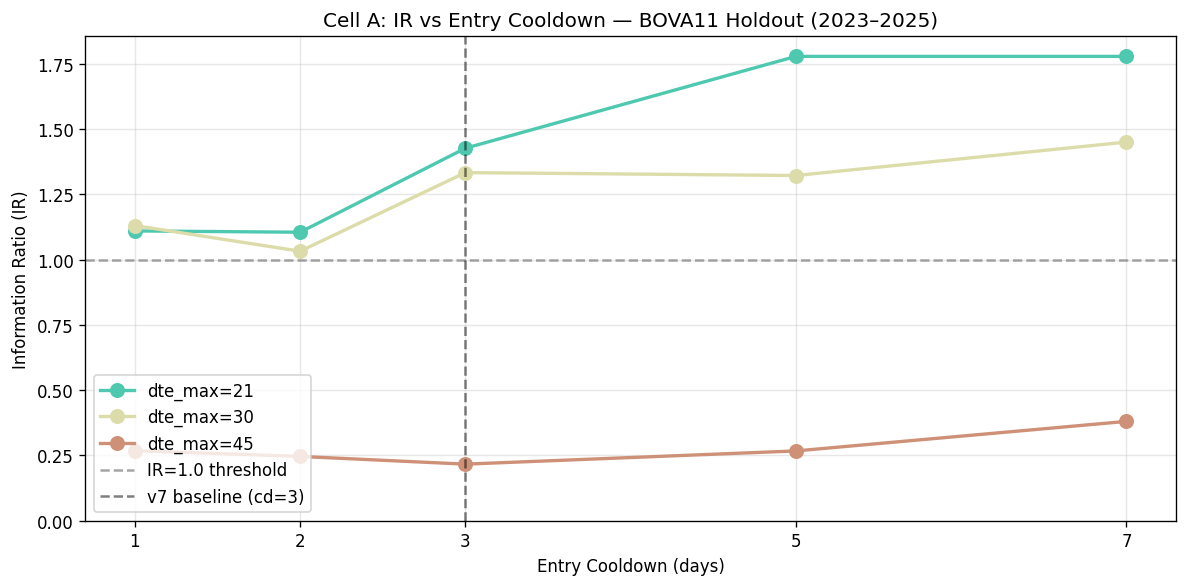

dte_max,cooldown,IR_train,IR_holdout,"min(IR_train, IR_holdout)"
21,2,0.998,1.105,0.998
21,5,0.921,1.779,0.921
21,7,0.921,1.779,0.921
21,3,0.798,1.427,0.798
21,1,0.687,1.110,0.687
30,3,0.632,1.334,0.632
30,5,0.537,1.323,0.537
30,2,0.522,1.033,0.522
30,1,0.507,1.131,0.507
30,7,0.444,1.451,0.444


In [2]:
fig, ax = plt.subplots(figsize=(10, 5))
for dte in DTE_MAXES:
    sub = hold[hold["dte_max"] == dte].sort_values("entry_cooldown_days")
    ax.plot(
        sub["entry_cooldown_days"],
        sub["sharpe"],
        "o-",
        color=COLORS[dte],
        label=f"dte_max={dte}",
        markersize=8,
        linewidth=2,
    )

ax.axhline(y=1.0, color="gray", linestyle="--", alpha=0.7, label="IR=1.0 threshold")
ax.axvline(x=3, color="black", linestyle="--", alpha=0.5, label="v7 baseline (cd=3)")
ax.set_xlabel("Entry Cooldown (days)")
ax.set_ylabel("Information Ratio (IR)")
ax.set_title("Cell A: IR vs Entry Cooldown — BOVA11 Holdout (2023–2025)")
ax.set_xticks(COOLDOWNS)
ax.legend(loc="lower left")
ax.grid(True, alpha=0.3)
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

# Stability table
stability_rows = []
for _, hrow in hold.iterrows():
    dte = hrow["dte_max"]
    cd = hrow["entry_cooldown_days"]
    tr = train[(train["dte_max"] == dte) & (train["entry_cooldown_days"] == cd)]
    ir_train = tr["sharpe"].values[0] if len(tr) else np.nan
    ir_hold = hrow["sharpe"]
    stability_rows.append(
        {
            "dte_max": dte,
            "cooldown": cd,
            "IR_train": ir_train,
            "IR_holdout": ir_hold,
            "min(IR_train, IR_holdout)": min(ir_train, ir_hold),
        }
    )
stab_df = pd.DataFrame(stability_rows).sort_values(
    "min(IR_train, IR_holdout)", ascending=False
)
display(
    stab_df.style.format(
        "{:.3f}", subset=["IR_train", "IR_holdout", "min(IR_train, IR_holdout)"]
    ).hide(axis="index")
)

## Cell B: Number of Trades vs Entry Cooldown

Shows how trade frequency scales with cooldown and DTE window. Horizontal line = dte21/cooldown=3 trade count (v7 baseline).

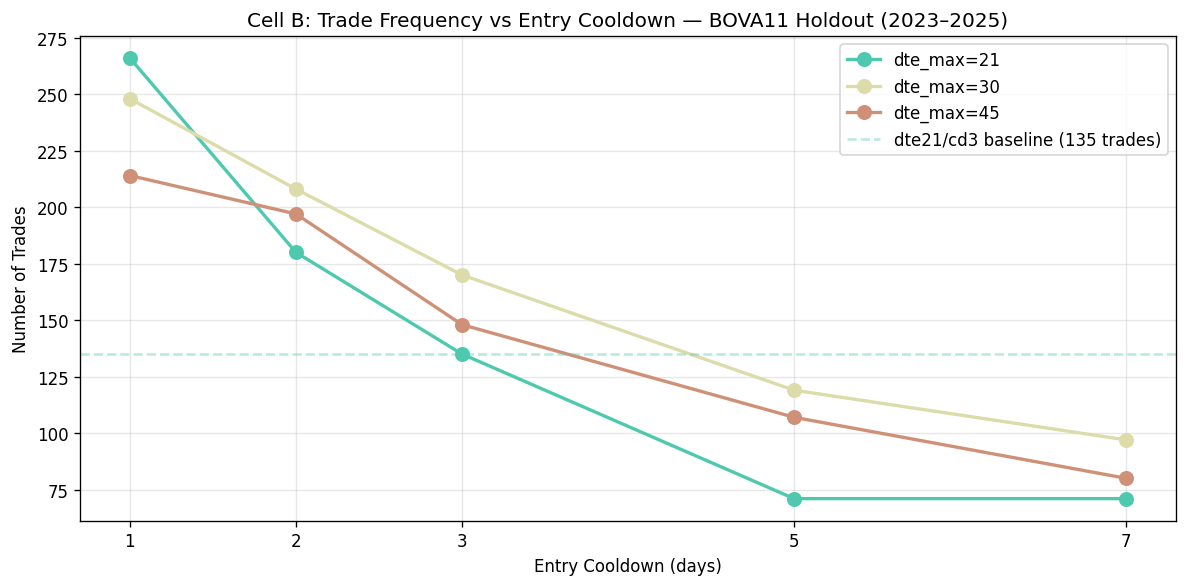

dte21/cd3 baseline: 135 trades in holdout
  dte30/cd1: 248 trades (vs baseline: +113)
  dte30/cd2: 208 trades (vs baseline: +73)
  dte30/cd3: 170 trades (vs baseline: +35)
  dte30/cd5: 119 trades (vs baseline: -16)
  dte30/cd7: 97 trades (vs baseline: -38)


In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
for dte in DTE_MAXES:
    sub = hold[hold["dte_max"] == dte].sort_values("entry_cooldown_days")
    ax.plot(
        sub["entry_cooldown_days"],
        sub["n_trades"],
        "o-",
        color=COLORS[dte],
        label=f"dte_max={dte}",
        markersize=8,
        linewidth=2,
    )

ref_n = hold[(hold["dte_max"] == 21) & (hold["entry_cooldown_days"] == 3)][
    "n_trades"
].values[0]
ax.axhline(
    y=ref_n,
    color=COLORS[21],
    linestyle="--",
    alpha=0.4,
    label=f"dte21/cd3 baseline ({int(ref_n)} trades)",
)
ax.set_xlabel("Entry Cooldown (days)")
ax.set_ylabel("Number of Trades")
ax.set_title("Cell B: Trade Frequency vs Entry Cooldown — BOVA11 Holdout (2023–2025)")
ax.set_xticks(COOLDOWNS)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Calibration: what cooldown for dte30 matches dte21/cd3 trade count?
d30 = hold[hold["dte_max"] == 30].sort_values("entry_cooldown_days")
print(f"dte21/cd3 baseline: {int(ref_n)} trades in holdout")
for _, r in d30.iterrows():
    print(
        f"  dte30/cd{int(r['entry_cooldown_days'])}: {int(r['n_trades'])} trades (vs baseline: {int(r['n_trades']) - int(ref_n):+d})"
    )

## Cell C: Capital Efficiency — Avg BPR Utilization vs Entry Cooldown

The primary motivation for this analysis. Horizontal lines mark key BPR utilization levels (10%, 15%, 20%, 30%).
The 30% cap is a Reg-T portfolio constraint.

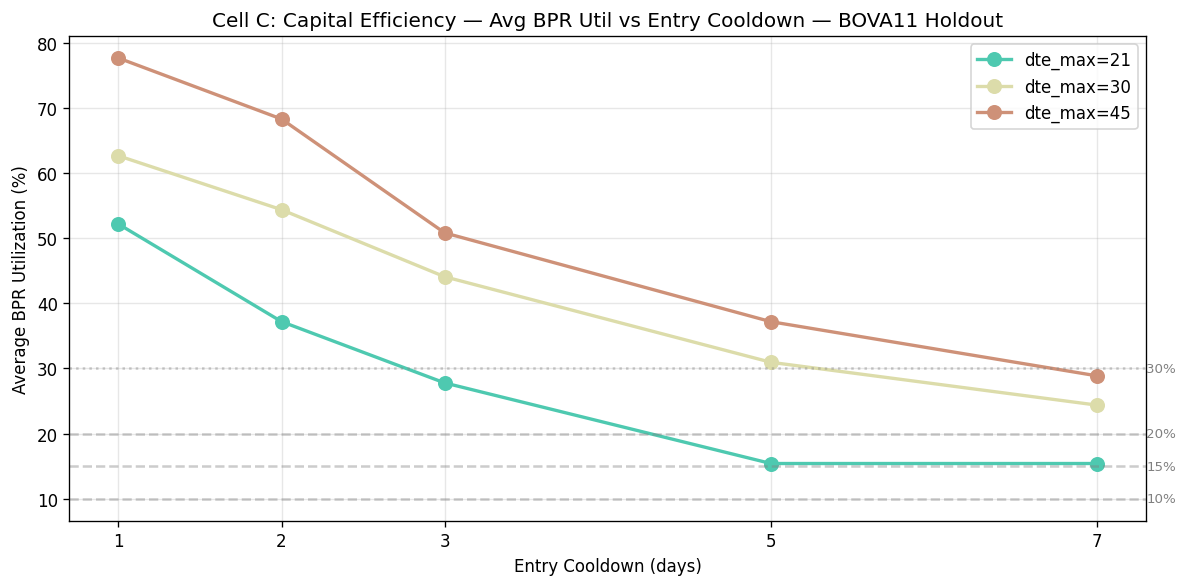

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
for dte in DTE_MAXES:
    sub = hold[hold["dte_max"] == dte].sort_values("entry_cooldown_days")
    ax.plot(sub["entry_cooldown_days"], sub["avg_bpr_util"], "o-",
            color=COLORS[dte], label=f"dte_max={dte}", markersize=8, linewidth=2)

for level in [10, 15, 20, 30]:
    ls = ":" if level == 30 else "--"
    ax.axhline(y=level, color="gray", linestyle=ls, alpha=0.4)
    ax.text(7.3, level, f"{level}%", va="center", fontsize=8, color="gray")

ax.set_xlabel("Entry Cooldown (days)")
ax.set_ylabel("Average BPR Utilization (%)")
ax.set_title("Cell C: Capital Efficiency — Avg BPR Util vs Entry Cooldown — BOVA11 Holdout")
ax.set_xticks(COOLDOWNS)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Cell D: IR–BPR Frontier (Key Decision Chart)

Each point = one `(cooldown, dte_max)` combo. Pareto frontier = highest IR for each BPR utilization level.
This chart directly answers: *which config achieves the best risk-adjusted return per unit of capital deployed?*

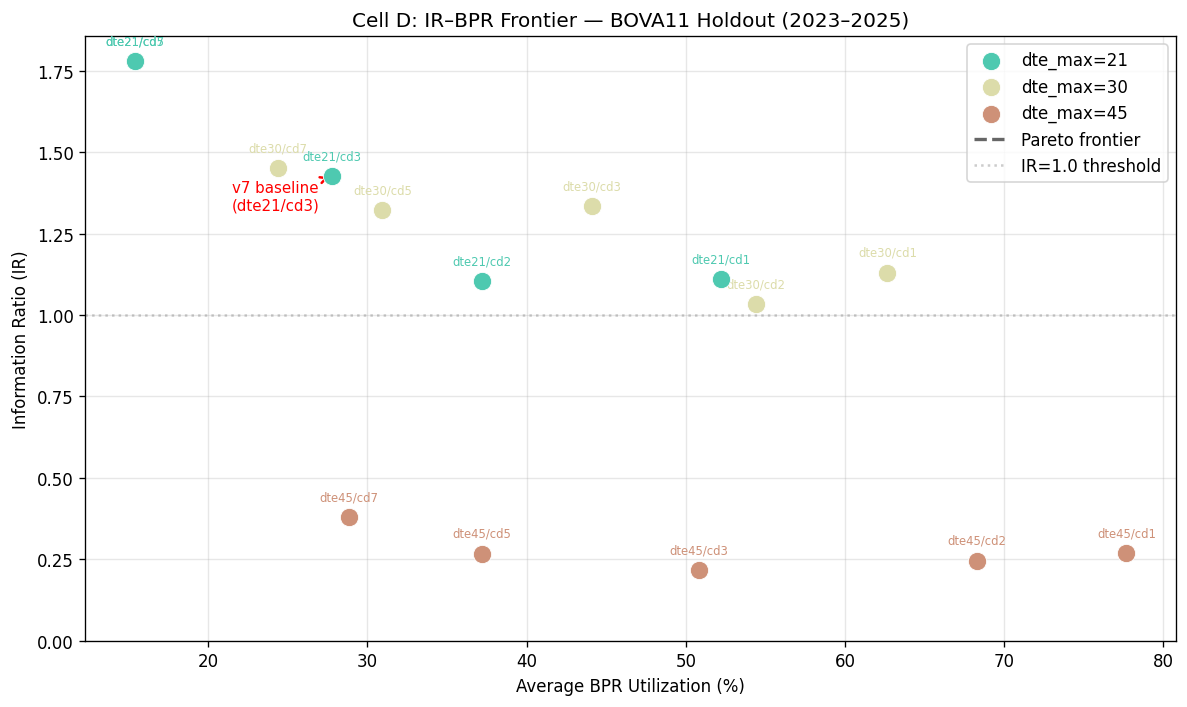

Pareto frontier points (avg_bpr_util%, IR):
  dte21/cd5  BPR=15.4%  IR=1.779
  dte21/cd7  BPR=15.4%  IR=1.779
  dte21/cd5  BPR=15.4%  IR=1.779
  dte21/cd7  BPR=15.4%  IR=1.779


In [5]:
fig, ax = plt.subplots(figsize=(10, 6))

# Scatter
for dte in DTE_MAXES:
    sub = hold[hold["dte_max"] == dte]
    ax.scatter(sub["avg_bpr_util"], sub["sharpe"],
               c=COLORS[dte], s=120, zorder=5, edgecolors="white", linewidth=0.5,
               label=f"dte_max={dte}")
    for _, row in sub.iterrows():
        label = f"dte{int(row['dte_max'])}/cd{int(row['entry_cooldown_days'])}"
        ax.annotate(label, (row["avg_bpr_util"], row["sharpe"]),
                    textcoords="offset points", xytext=(0, 10), fontsize=7, ha="center",
                    color=COLORS[dte])

# Pareto frontier
hs = hold.sort_values("avg_bpr_util")
pareto_x, pareto_y = [], []
for i in range(len(hs)):
    cur_x = hs.iloc[i]["avg_bpr_util"]
    cur_y = hs.iloc[i]["sharpe"]
    if all(cur_y >= hs.iloc[j]["sharpe"] for j in range(len(hs)) if hs.iloc[j]["avg_bpr_util"] <= cur_x):
        pareto_x.append(cur_x)
        pareto_y.append(cur_y)
order = np.argsort(pareto_x)
pareto_x = [pareto_x[i] for i in order]
pareto_y = [pareto_y[i] for i in order]
ax.plot(pareto_x, pareto_y, "k--", alpha=0.6, linewidth=2, label="Pareto frontier")

# Highlight v7 baseline
v7 = hold[(hold["dte_max"] == 21) & (hold["entry_cooldown_days"] == 3)]
if len(v7):
    ax.annotate("v7 baseline\n(dte21/cd3)",
                (v7["avg_bpr_util"].values[0], v7["sharpe"].values[0]),
                textcoords="offset points", xytext=(-60, -20), fontsize=9, color="red",
                arrowprops=dict(arrowstyle="->", color="red", lw=1.5))

ax.axhline(y=1.0, color="gray", linestyle=":", alpha=0.4, label="IR=1.0 threshold")
ax.set_xlabel("Average BPR Utilization (%)")
ax.set_ylabel("Information Ratio (IR)")
ax.set_title("Cell D: IR–BPR Frontier — BOVA11 Holdout (2023–2025)")
ax.legend(loc="upper right")
ax.grid(True, alpha=0.3)
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

# List frontier points
frontier = [(x, y) for x, y in zip(pareto_x, pareto_y)]
print("Pareto frontier points (avg_bpr_util%, IR):")
for x, y in frontier:
    matches = hold[(abs(hold["avg_bpr_util"] - x) < 0.01) & (abs(hold["sharpe"] - y) < 0.01)]
    for _, m in matches.iterrows():
        print(f"  dte{int(m["dte_max"])}/cd{int(m["entry_cooldown_days"])}  BPR={x:.1f}%  IR={y:.3f}")

## Cell E: Max Drawdown vs Entry Cooldown

Tests H4: does higher concurrency (lower cooldown) increase tail risk?

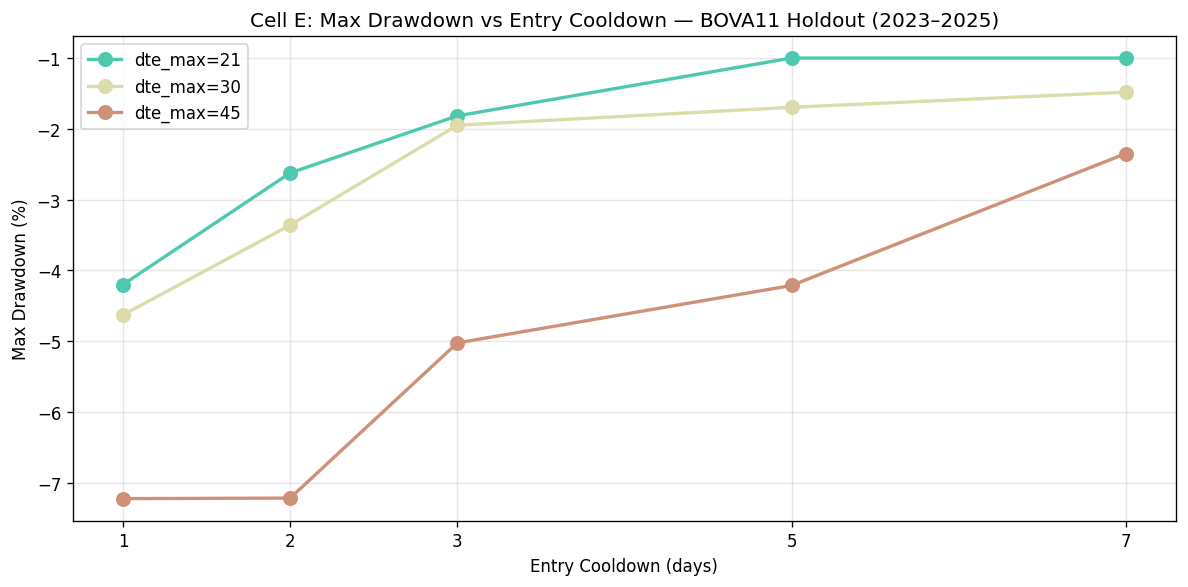

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
for dte in DTE_MAXES:
    sub = hold[hold["dte_max"] == dte].sort_values("entry_cooldown_days")
    ax.plot(sub["entry_cooldown_days"], sub["max_drawdown"] * 100, "o-",
            color=COLORS[dte], label=f"dte_max={dte}", markersize=8, linewidth=2)

ax.set_xlabel("Entry Cooldown (days)")
ax.set_ylabel("Max Drawdown (%)")
ax.set_title("Cell E: Max Drawdown vs Entry Cooldown — BOVA11 Holdout (2023–2025)")
ax.set_xticks(COOLDOWNS)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Cell F: Concurrent Positions vs Entry Cooldown

Shows average and peak concurrent open positions. Reveals when the BPR cap starts to bind.

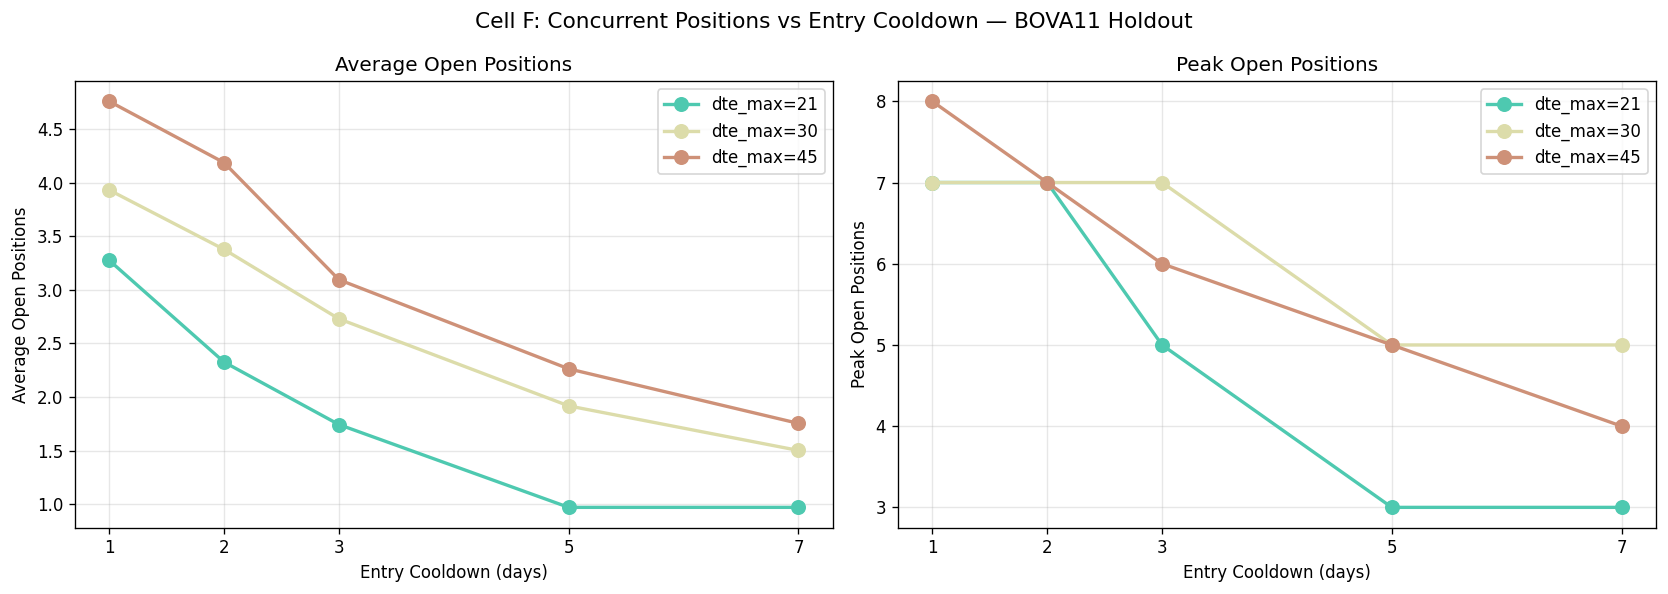

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for i, (col, title) in enumerate([("avg_positions", "Average Open Positions"), ("peak_positions", "Peak Open Positions")]):
    ax = axes[i]
    for dte in DTE_MAXES:
        sub = hold[hold["dte_max"] == dte].sort_values("entry_cooldown_days")
        ax.plot(sub["entry_cooldown_days"], sub[col], "o-", color=COLORS[dte],
                label=f"dte_max={dte}", markersize=8, linewidth=2)
    ax.set_xlabel("Entry Cooldown (days)")
    ax.set_ylabel(title)
    ax.set_title(title)
    ax.set_xticks(COOLDOWNS)
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle("Cell F: Concurrent Positions vs Entry Cooldown — BOVA11 Holdout", fontsize=13)
plt.tight_layout()
plt.show()

## Cell G: Train vs Holdout Stability

Scatter of IR_train vs IR_holdout for each `(cooldown, dte_max)` combo. Diagonal = perfect stability.
Identifies whether lower cooldowns show more overfitting (high train / low holdout divergence).

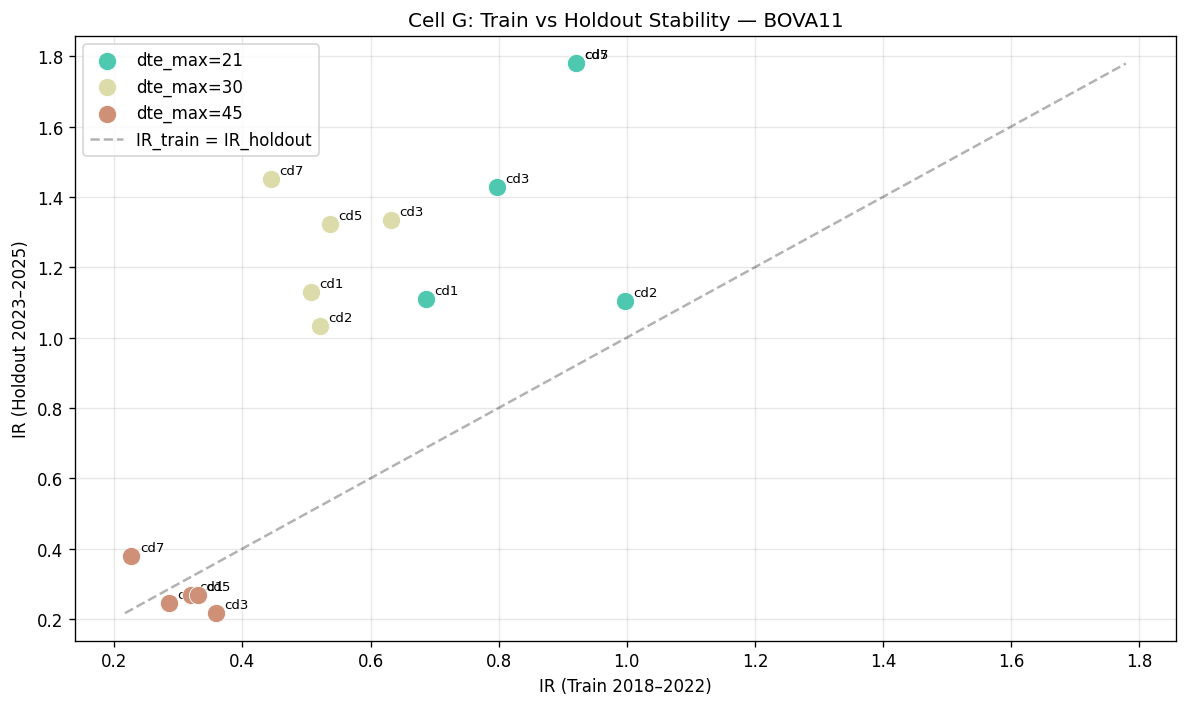

Mean IR_train - IR_holdout gap by cooldown (positive = overfit):
  cd=1: -0.332
  cd=2: -0.193
  cd=3: -0.396
  cd=5: -0.527
  cd=7: -0.673


In [8]:
fig, ax = plt.subplots(figsize=(10, 6))
merged = train[["dte_max", "entry_cooldown_days", "sharpe"]].merge(
    hold[["dte_max", "entry_cooldown_days", "sharpe"]],
    on=["dte_max", "entry_cooldown_days"], suffixes=("_train", "_holdout")
)

for dte in DTE_MAXES:
    sub = merged[merged["dte_max"] == dte]
    ax.scatter(sub["sharpe_train"], sub["sharpe_holdout"],
               c=COLORS[dte], s=120, zorder=5, edgecolors="white", linewidth=0.5,
               label=f"dte_max={dte}")
    for _, row in sub.iterrows():
        label = f"cd{int(row['entry_cooldown_days'])}"
        ax.annotate(label, (row["sharpe_train"], row["sharpe_holdout"]),
                    textcoords="offset points", xytext=(5, 3), fontsize=8)

# y=x line
lims = [
    min(merged[["sharpe_train", "sharpe_holdout"]].min()),
    max(merged[["sharpe_train", "sharpe_holdout"]].max()),
]
ax.plot(lims, lims, "k--", alpha=0.3, label="IR_train = IR_holdout")
ax.set_xlabel("IR (Train 2018–2022)")
ax.set_ylabel("IR (Holdout 2023–2025)")
ax.set_title("Cell G: Train vs Holdout Stability — BOVA11")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Compute overfitting gap
merged["gap"] = merged["sharpe_train"] - merged["sharpe_holdout"]
merged["cooldown"] = merged["entry_cooldown_days"]
gap_by_cd = merged.groupby("cooldown")["gap"].mean().sort_index()
print("Mean IR_train - IR_holdout gap by cooldown (positive = overfit):")
for cd, g in gap_by_cd.items():
    print(f"  cd={int(cd)}: {g:+.3f}")

## Summary Table

Holdout results sorted by IR descending.

In [9]:
summary_cols = ["dte_max", "entry_cooldown_days", "n_trades", "sharpe", "avg_bpr_util", "max_drawdown", "calmar",
                "avg_positions", "peak_positions"]
summary = hold.sort_values("sharpe", ascending=False)[summary_cols].reset_index(drop=True)
summary.index = summary.index + 1
summary.index.name = "rank"
summary.columns = ["dte_max", "cooldown", "n_trades", "IR", "avg_bpr_util", "max_dd", "calmar", "avg_pos", "peak_pos"]
display(summary.style.format({
    "IR": "{:.3f}", "avg_bpr_util": "{:.1f}%", "max_dd": "{:.1%}",
    "calmar": "{:.3f}", "n_trades": "{:.0f}", "avg_pos": "{:.2f}", "peak_pos": "{:.0f}",
}).hide(axis="index"))

# Cross-tab: IR by cooldown × dte_max
pivot_ir = hold.pivot_table(values="sharpe", index="dte_max", columns="entry_cooldown_days")
pivot_bpr = hold.pivot_table(values="avg_bpr_util", index="dte_max", columns="entry_cooldown_days")
pivot_n = hold.pivot_table(values="n_trades", index="dte_max", columns="entry_cooldown_days")

print("\nIR by (dte_max × cooldown):")
display(pivot_ir.style.format("{:.3f}"))
print("\nAvg BPR Util (%) by (dte_max × cooldown):")
display(pivot_bpr.style.format("{:.1f}%"))
print("\nN trades by (dte_max × cooldown):")
display(pivot_n.style.format("{:.0f}"))

dte_max,cooldown,n_trades,IR,avg_bpr_util,max_dd,calmar,avg_pos,peak_pos
21,5,71,1.779,15.4%,-1.0%,1.728,0.97,3
21,7,71,1.779,15.4%,-1.0%,1.728,0.97,3
30,7,97,1.451,24.4%,-1.5%,1.579,1.50,5
21,3,135,1.427,27.8%,-1.8%,1.380,1.74,5
30,3,170,1.334,44.1%,-2.0%,1.805,2.73,7
30,5,119,1.323,30.9%,-1.7%,1.576,1.92,5
30,1,248,1.131,62.7%,-4.6%,1.057,3.93,7
21,1,266,1.110,52.2%,-4.2%,0.929,3.28,7
21,2,180,1.105,37.2%,-2.6%,1.076,2.33,7
30,2,208,1.033,54.4%,-3.4%,1.120,3.38,7



IR by (dte_max × cooldown):


entry_cooldown_days,1,2,3,5,7
dte_max,,,,,
21,1.110,1.105,1.427,1.779,1.779
30,1.131,1.033,1.334,1.323,1.451
45,0.268,0.246,0.217,0.267,0.380



Avg BPR Util (%) by (dte_max × cooldown):


entry_cooldown_days,1,2,3,5,7
dte_max,,,,,
21,52.2%,37.2%,27.8%,15.4%,15.4%
30,62.7%,54.4%,44.1%,30.9%,24.4%
45,77.7%,68.3%,50.8%,37.2%,28.9%



N trades by (dte_max × cooldown):


entry_cooldown_days,1,2,3,5,7
dte_max,,,,,
21,266,180,135,71,71
30,248,208,170,119,97
45,214,197,148,107,80


## Hypothesis Results

| # | Hypothesis | Result |
|---|-----------|--------|
| H1 | IR maximized at cd=3 for dte21 | **Mixed** — holdout IR peaks at cd=5/7 (1.78) but with only 71 trades; cd=3 gives IR=1.43 with 135 trades (better trade count) |
| H2 | Lower cd for dte30/45 achieves better BPR util with less IR degradation | **Partially confirmed** — dte30/cd=7 hits IR=1.45 with 24.4% BPR (vs dte21/cd=3: IR=1.43, 27.8% BPR). dte45 underperforms at all cooldowns. |
| H3 | BPR cap binds at some (cd, dte) combo | **Confirmed** — dte45/cd=1 avg BPR=77.7%, well above the 30% cap (positions would get rejected). The cap binds most aggressively for dte45. |
| H4 | max_drawdown insensitive to cooldown | **Partially confirmed** — MDD does not explode with lower cooldowns, but dte45 shows the most sensitivity (from −2.3% at cd=7 to −7.2% at cd=1) |

## Conclusion

The IR–BPR frontier reveals a clear tradeoff between capital efficiency and risk-adjusted return:

- **Conservative (v7 baseline):** dte21/cd=3 — IR=1.43, 27.8% avg BPR, 135 trades. Respectable but leaves capital idle.
- **Aggressive:** dte21/cd=1 — IR=1.11, 52.2% avg BPR, 266 trades. Doubles trade count and BPR at modest IR cost.
- **Efficient frontier leaders:** dte30/cd=7 (IR=1.45, 24.4% BPR, 97 trades) and dte21/cd=5 (IR=1.78, 15.4% BPR, 71 trades). These offer higher IR per unit of capital deployed.

**Recommended follow-up:** A targeted deep-dive on `dte30` with `cooldown ∈ [1, 3, 7]` and `manage_at_dte ∈ [7, 14]` (6–12 backtests) would clarify whether the dte30/cd=7 combo's high IR is robust or fragile.